# Plotting PDFs, saving PDF files

In [1]:
fmap={'g':0,'u':1,'d':2,'s':3,'c':4,'b':5,'bb':-5,'cb':-4,'sb':-3,'db':-2,'ub':-1}   # this is fmap adopted in fitpack_legacy

In [2]:
import sys,os,time
import numpy as np
from mpmath import fp
# from numba import jit
import pandas as pd
import copy

import lhapdf

#--matplotlib
import matplotlib
matplotlib.rcParams['text.latex.preamble']=r"\usepackage{amsmath}"
matplotlib.rc('text',usetex=True)
import pylab  as py
from matplotlib.lines import Line2D

#--fitting
from scipy.optimize import least_squares
from scipy.integrate import quad,fixed_quad

In [6]:
path='/work/JAM/barryp/JAM/fitpack_legacy_dev'

In [7]:
sys.path.insert(0, path)

In [8]:
from qcdlib.aux import AUX
from qcdlib.pdf import PDF
from qcdlib.mellin import MELLIN
from qcdlib.alphaS import ALPHAS
import qcdlib.tmd_ZETA as tmd
# import qcdlib.params as par
from qcdlib import alphaS
# from tools.replicas import REPLICAS

In [9]:
from tools.config import conf
from tools.tools import checkdir,lprint

In [10]:
os.environ['FITPACK']=path
os.environ['LHAPDF_DATA_PATH']='/work/JAM/JAM/apps/lhapdf_tables/'
os.environ['LHAPDF_DATA_PATH']='/work/JAM/barryp/misc/:'+os.environ['LHAPDF_DATA_PATH']
os.environ['LHAPDF_DATA_PATH']='/work/JAM/JAM/apps/lhapdf_tables/more/more1:'+os.environ['LHAPDF_DATA_PATH']
# os.environ['LHAPDF_DATA_PATH']='/work/JAM/barryp/JAM/fitpack_legacy_dev/dev/dy_qT/PDFs/:'+os.environ['LHAPDF_DATA_PATH']
os.environ["PATH"]='/work/JAM/JAM/apps/bin:'+os.environ["PATH"]

In [11]:
from obslib.dy_qT.theory import HARD_FACTOR,FIDUCIAL,EWEAK_COUPLING,LeptonCutsDY
from obslib.dy_qT.theory import THEORY_ZETA as THEORY
from obslib.dy_qT.theory import THEORY_CSS

In [12]:
from qcdlib import tmd_ZETA as tmdzeta

In [13]:
from fitlib.resman import RESMAN

In [14]:
trey = np.load('/work/JAM/share/replicas/treyand24-nosidis/treyand-24-nosidis.npy',allow_pickle=True,encoding='latin1').item()

In [15]:
conf.update(trey['conf'])
conf['order']='LO'

In [16]:
resman = RESMAN(nworkers=1,parallel=False,datasets=False)

# Look at Trey's PDFs

In [14]:
# print(np.linspace(0.4,1,100))#[1:])

In [17]:
flavs = ['uv','dv','ub','db','s','sb','c','cb','b','bb','g']

Q2 = [conf['Q20'],10,15,20,30,40,50,60,70,80,90,100,200,300,400,500,600,700,800,900,1000,2000,3000,4000]

#X = 10**np.linspace(-4,np.log10(0.4),100)
#X = np.append(X,np.linspace(0.4,1,101)[1:])
X = 10**np.linspace(-4,np.log10(1),200)

treypdf = {}
for q2 in Q2:
    treypdf[q2]={}
    for f in flavs:
        treypdf[q2][f]=[]

for irep in range(len(trey['params'])):
    lprint('progress: %i/%i'%(irep,len(trey['params'])))
    for i,o in enumerate(trey['order']):
        if o[0]==2: continue
        if o[1]=='pdf':
            for k in conf['params']['pdf']:
                if o[2]==k:
                    conf['params']['pdf'][k]['value'] = trey['params'][irep][i]

    resman.parman.get_ordered_free_params()

    for q2 in Q2:
        for f in flavs:
            treypdf[q2][f].append(np.array([conf['pdf'].get_xF(_,q2,f) for _ in X]))


progress: 1195/1196

In [18]:
for q2 in treypdf:
    for f in treypdf[q2]:
        treypdf[q2][f]=np.array(treypdf[q2][f])

In [19]:
np.save('trey24_no_sidis_lo.npy',treypdf)

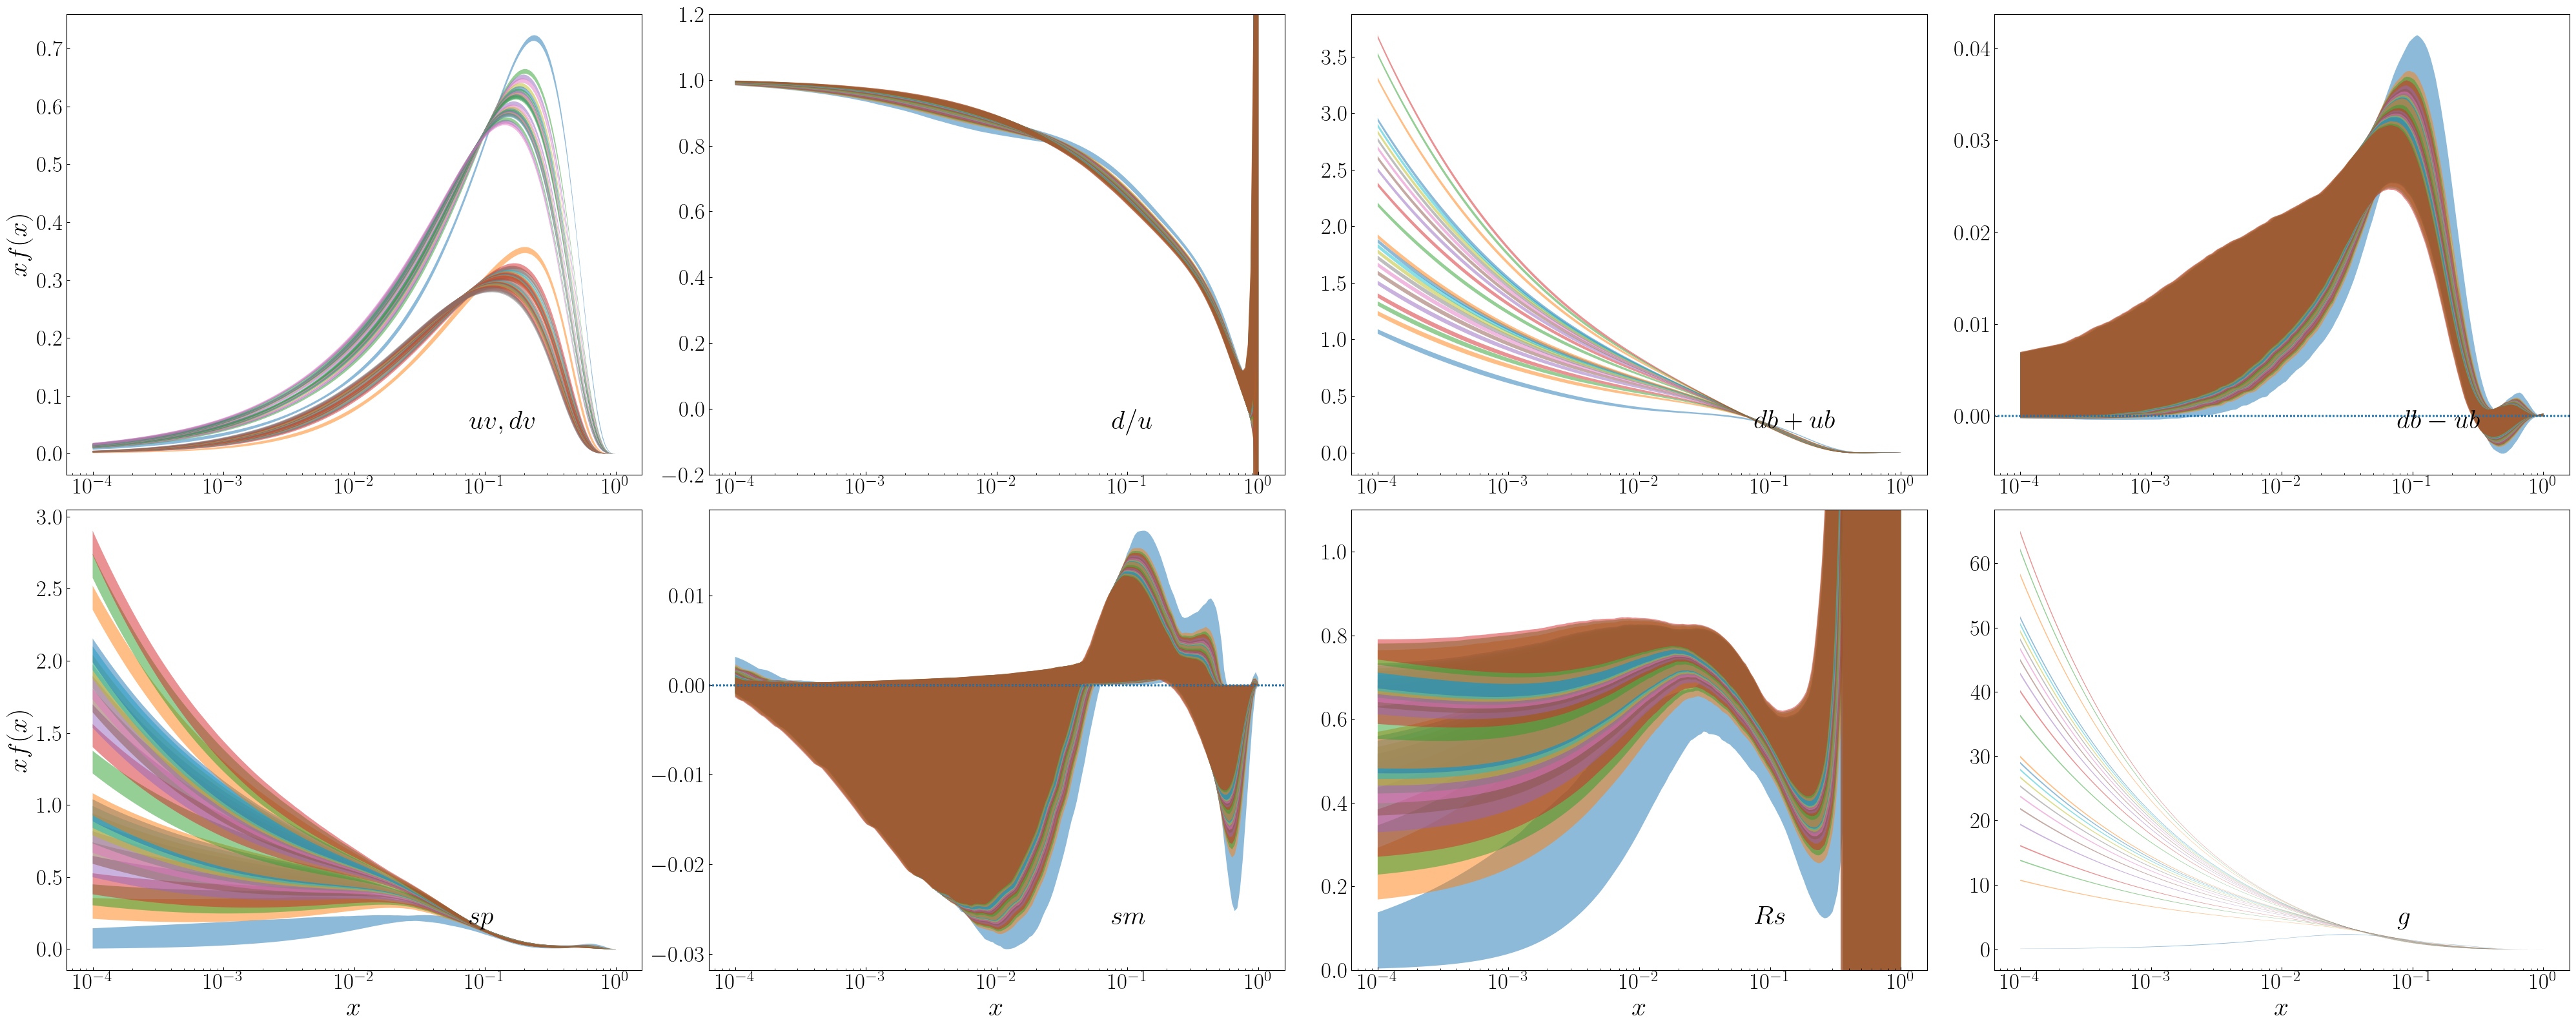

In [20]:
nrows,ncols=2,4
py.figure(figsize=(10*ncols,8*nrows))
cnt=0

plot_flavs=['uv,dv','d/u','db+ub','db-ub','sp','sm','Rs','g']
lower_num = 0.025
upper_num = 0.975

for f in plot_flavs:
    cnt+=1
    ax=py.subplot(nrows,ncols,cnt)
    for q2 in Q2:

        if f=='uv,dv':
            pdf = treypdf[q2]['uv']
            lower,upper = np.quantile(pdf,lower_num,axis=0),np.quantile(pdf,upper_num,axis=0)
            ax.fill_between(X,lower,upper,alpha=0.5)
            pdf = treypdf[q2]['dv']
            lower,upper = np.quantile(pdf,lower_num,axis=0),np.quantile(pdf,upper_num,axis=0)
            ax.fill_between(X,lower,upper,alpha=0.5)

            
            # ax.set_ylim(0,0.7)
        elif f=='d/u':
            d = treypdf[q2]['dv'] + treypdf[q2]['db']
            u = treypdf[q2]['uv'] + treypdf[q2]['ub']
            donu = d/u
            lower,upper = np.quantile(donu,lower_num,axis=0),np.quantile(donu,upper_num,axis=0)
            ax.fill_between(X,lower,upper,alpha=0.5)
            ax.set_ylim(-0.2,1.2)
            
        elif f=='db+ub':
            pdf = treypdf[q2]['db'] + treypdf[q2]['ub']
            lower,upper = np.quantile(pdf,lower_num,axis=0),np.quantile(pdf,upper_num,axis=0)
            ax.fill_between(X,lower,upper,alpha=0.5)
            
        elif f=='db-ub':
            pdf = treypdf[q2]['db'] - treypdf[q2]['ub']
            lower,upper = np.quantile(pdf,lower_num,axis=0),np.quantile(pdf,upper_num,axis=0)
            ax.fill_between(X,lower,upper,alpha=0.5)
            
            ax.axhline(y=0,ls=':')
        elif f=='sp':
            pdf = treypdf[q2]['s'] + treypdf[q2]['sb']
            lower,upper = np.quantile(pdf,lower_num,axis=0),np.quantile(pdf,upper_num,axis=0)
            ax.fill_between(X,lower,upper,alpha=0.5)
            
        elif f=='sm':
            pdf = treypdf[q2]['s'] - treypdf[q2]['sb']
            lower,upper = np.quantile(pdf,lower_num,axis=0),np.quantile(pdf,upper_num,axis=0)
            ax.fill_between(X,lower,upper,alpha=0.5)
            
            ax.axhline(y=0,ls=':')
        elif f=='Rs':
            num = treypdf[q2]['s'] + treypdf[q2]['sb']
            den = treypdf[q2]['ub'] + treypdf[q2]['db']
            pdf = num/den
            lower,upper = np.quantile(pdf,lower_num,axis=0),np.quantile(pdf,upper_num,axis=0)
            ax.fill_between(X,lower,upper,alpha=0.5)
            
            ax.set_ylim(0,1.1)
        elif f=='g':
            pdf = treypdf[q2]['g']
            lower,upper = np.quantile(pdf,lower_num,axis=0),np.quantile(pdf,upper_num,axis=0)
            ax.fill_between(X,lower,upper,alpha=0.5)
            
            
    ax.tick_params(direction='in',labelsize=18)
    if cnt>4: ax.set_xlabel(r'$x$',size=30)
    if cnt in [1,5]: ax.set_ylabel(r'$xf(x)$',size=30)
    ax.text(0.7,0.1,r'$%s$'%f,transform=ax.transAxes,size=30)
    #ax.legend(fontsize=16,ncols=3,loc='upper left')
    ax.semilogx()
    # ax.set_xlim(0.01,0.4)
    ax.tick_params(direction='in',labelsize=25,axis='both',which='both')
    # ax.set_ylim(0,2)
    #ax.axhline(y=1)
py.tight_layout()        